# Qwen3-30B-A3B-Base: architecture and pruning targets

Both Minitron papers ([2407.14679](../docs/papers/2407.14679-compact-lms-pruning-distillation.pdf),
[2408.11796](../docs/papers/2408.11796-minitron-approach.pdf)) prune dense
transformers. Before writing any pruning code against Qwen3-30B-A3B-Base — an
MoE model — this notebook confirms, against the real `transformers` module
structure rather than the config file alone, which weight tensors correspond
to which pruning axis, and whether the papers' assumptions (one MLP per layer,
no shared expert) hold here.

No weights are downloaded. `AutoConfig.from_pretrained` only fetches
`config.json`, and building the model on `meta` device allocates every tensor
as a shape and a dtype, never real memory.

In [1]:
from bonsai.architecture import summarize

summary = summarize("Qwen/Qwen3-30B-A3B-Base")
summary.num_layers, summary.num_experts, summary.experts_per_token, summary.hidden_size

(48, 128, 8, 2048)

## Is every layer sparse?

Reading `Qwen3MoeDecoderLayer.__init__` directly: a layer only gets a
`Qwen3MoeSparseMoeBlock` (the MoE block) when its index isn't in
`config.mlp_only_layers` *and* it lands on `config.decoder_sparse_step`.
Otherwise it falls back to an ordinary dense `Qwen3MoeMLP` — the kind of layer
both papers already know how to prune. Worth checking per-model rather than
assuming: a different Qwen3-MoE checkpoint could set `mlp_only_layers`
non-empty and mix dense and sparse layers.

In [2]:
sparse_layers = [layer.layer_idx for layer in summary.layers if layer.is_sparse]
dense_layers = [layer.layer_idx for layer in summary.layers if not layer.is_sparse]
print(f"sparse (MoE) layers: {len(sparse_layers)} / {summary.num_layers}")
print(f"dense layers: {dense_layers or 'none'}")

sparse (MoE) layers: 48 / 48
dense layers: none


All 48 layers are sparse. `mlp_only_layers` is empty and `decoder_sparse_step`
is 1 in this model's config, so there's no dense-MLP layer to special-case —
every layer's width-pruning story is the expert story, not the ordinary-MLP
story the papers describe.

## Total vs. active parameters

This is the number that makes expert pruning a different kind of lever than
depth or width pruning. Depth and width pruning cut both total and active
parameters together — remove a layer or a head, and every token stops paying
for it. Expert pruning only cuts *total*: the experts a given token doesn't
route to were never in its active path, so removing an unused expert changes
memory footprint without touching that token's compute.

In [3]:
active_fraction = summary.experts_per_token / summary.num_experts
active_experts_params = summary.experts_total * active_fraction
active_total = summary.attention_total + summary.router_total + active_experts_params
active_total += summary.embedding + summary.lm_head

print(f"total params:          {summary.total / 1e9:6.2f}B")
print(
    f"active params (approx): {active_total / 1e9:6.2f}B  "
    f"({summary.experts_per_token} of {summary.num_experts} experts/token)"
)
print(f"experts' share of total: {summary.experts_total / summary.total:.1%}")

total params:           30.53B
active params (approx):   3.35B  (8 of 128 experts/token)
experts' share of total: 95.0%


~95% of the model's parameters are experts. Qwen's own "A3B" naming
(~3B active out of ~30B total) checks out against the actual module shapes,
not just the published number.

## Where the parameters live, by axis

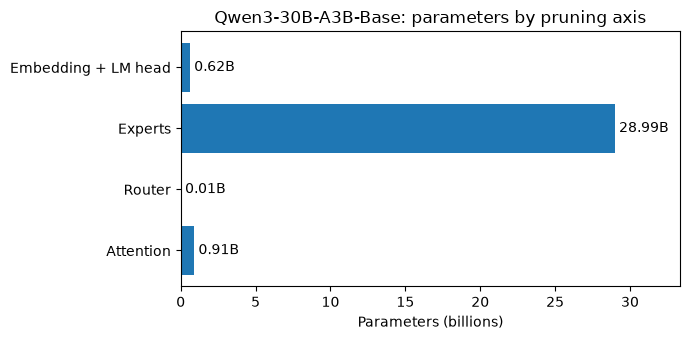

In [4]:
import matplotlib.pyplot as plt

axes = ["Attention", "Router", "Experts", "Embedding + LM head"]
values = [
    summary.attention_total,
    summary.router_total,
    summary.experts_total,
    summary.embedding + summary.lm_head,
]

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(axes, [v / 1e9 for v in values])
ax.set_xlabel("Parameters (billions)")
ax.set_title("Qwen3-30B-A3B-Base: parameters by pruning axis")
ax.bar_label(bars, fmt="%.2fB", padding=3)
ax.set_xlim(0, max(values) / 1e9 * 1.15)
fig.tight_layout()
plt.show()

## Pruning targets for each axis

Mapping each axis in the papers (and the expert axis neither paper has) to
the actual tensors, confirmed against `modeling_qwen3_moe.py`:

| Axis | Paper | Tensors | What changes |
| --- | --- | --- | --- |
| Depth | 2407.14679 §2.2 (PPL/BI); 2408.11796 (downstream-task, contiguous blocks) | whole `Qwen3MoeDecoderLayer` blocks | remove layers from `model.layers`; update `num_hidden_layers` |
| Attention width | 2407.14679 §2.2 ("Width: heads") | `self_attn.{q,k,v,o}_proj` rows/columns for the pruned heads | fewer rows in `q_proj`/`k_proj`/`v_proj`, fewer columns in `o_proj`; update `num_attention_heads` |
| Experts (new) | neither paper — this project's addition | `mlp.experts.gate_up_proj`, `mlp.experts.down_proj`, sliced on dim 0 | drop the pruned experts' slices; shrink `mlp.gate.weight` (the router) to match; update `num_experts` |

The expert case is the one with no prior art to check against: `gate_up_proj`
and `down_proj` are **batched parameter tensors** (shape
`[num_experts, ...]`), not 128 separate submodules per layer. Pruning an
expert is a slice along dimension 0, not deleting an item from a list of
submodules — confirmed by reading `Qwen3MoeExperts.__init__` directly rather
than assumed from the config.

There's no shared-expert tensor to account for either (unlike, e.g.,
DeepSeek-V2's architecture) — `Qwen3MoeSparseMoeBlock` holds exactly a router
and the experts, nothing else.